In [ ]:
# script for downloading NASA GEX-NDDP data

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import requests

import os
import warnings
warnings.filterwarnings('ignore')
from urllib.parse import urlencode, urljoin
from urllib.request import urlopen

from cartopy import crs as ccrs, feature as cfeature
import netCDF4
from netCDF4 import Dataset
from datetime import datetime as dt
import xarray as xr

## Change path to correct data directory

In [2]:
! pwd

/Users/tedscott/Google Drive/My Drive/PhD Work/Codes/HeatWaves/HeatWaves


In [2]:
# example URL: https://ds.nccs.nasa.gov/thredds/fileServer/AMES/NEX/GDDP-CMIP6/CESM2/historical/r4i1p1f1/tas/tas_day_CESM2_historical_r4i1p1f1_gn_1962_v2.0.nc
# os.mkdir('../../FGOALS-g3')
# os.mkdir('../../FGOALS-g3/raw')
# os.mkdir('../../FGOALS-g3/regridded')
os.chdir('../../../Data/CMIP6/NEX-GDDP-CMIP6/NorESM2-LM/raw')
#os.chdir('../../MIROC6/raw/')
! ls -al

total 17957952
drwxr-xr-x@ 89 tedscott  staff       2848 Nov 21 07:09 .
drwxr-xr-x@  5 tedscott  staff        160 Oct  9 11:04 ..
-rw-r--r--@  1 tedscott  staff       6148 Oct 15 08:54 .DS_Store
-rw-r--r--@  1 tedscott  staff  242086536 Nov 20 10:10 tas_day_NorESM2-LM_ssp585_r1i1p1f1_gn_2015_v2.0.nc
-rw-r--r--@  1 tedscott  staff  242107400 Nov 20 10:26 tas_day_NorESM2-LM_ssp585_r1i1p1f1_gn_2016_v2.0.nc
-rw-r--r--@  1 tedscott  staff  242106973 Nov 20 10:41 tas_day_NorESM2-LM_ssp585_r1i1p1f1_gn_2017_v2.0.nc
-rw-r--r--@  1 tedscott  staff  242148294 Nov 20 10:57 tas_day_NorESM2-LM_ssp585_r1i1p1f1_gn_2018_v2.0.nc
-rw-r--r--@  1 tedscott  staff  242084182 Nov 20 11:12 tas_day_NorESM2-LM_ssp585_r1i1p1f1_gn_2019_v2.0.nc
-rw-r--r--@  1 tedscott  staff  242039406 Nov 20 11:27 tas_day_NorESM2-LM_ssp585_r1i1p1f1_gn_2020_v2.0.nc
-rw-r--r--@  1 tedscott  staff  242046347 Nov 20 11:41 tas_day_NorESM2-LM_ssp585_r1i1p1f1_gn_2021_v2.0.nc
-rw-r--r--@  1 tedscott  staff  242001161 Nov 20 11:58 tas_day_

## Download files

In [4]:
process_yrs = np.arange(2015,2101,1)
#process_yrs = [1988]
process_yrs

array([2015, 2016, 2017, 2018, 2019, 2020, 2021, 2022, 2023, 2024, 2025,
       2026, 2027, 2028, 2029, 2030, 2031, 2032, 2033, 2034, 2035, 2036,
       2037, 2038, 2039, 2040, 2041, 2042, 2043, 2044, 2045, 2046, 2047,
       2048, 2049, 2050, 2051, 2052, 2053, 2054, 2055, 2056, 2057, 2058,
       2059, 2060, 2061, 2062, 2063, 2064, 2065, 2066, 2067, 2068, 2069,
       2070, 2071, 2072, 2073, 2074, 2075, 2076, 2077, 2078, 2079, 2080,
       2081, 2082, 2083, 2084, 2085, 2086, 2087, 2088, 2089, 2090, 2091,
       2092, 2093, 2094, 2095, 2096, 2097, 2098, 2099, 2100])

In [ ]:
%%time
# taking roughly 9 min per file on 2026-10-06
# help from https://realpython.com/python-download-file-from-url/#downloading-a-large-file-in-a-streaming-fashion

scenario = "ssp585"#"historical"#"ssp245""ssp370"#
realization = "r1i1p1f1"#"r4i1p1f1"
model = "GFDL-ESM4"#"CanESM5"#"CESM2"
grid = "gr1"#"gr1"#"gn"

for yr in process_yrs:

    start = dt.now()
    
    filename = "tas_day_"+model+"_"+scenario+"_"+realization+"_"+grid+"_"+str(yr)+"_v2.0.nc"
    url = "https://ds.nccs.nasa.gov/thredds/fileServer/AMES/NEX/GDDP-CMIP6/"+model+"/"+scenario+"/"+realization+"/tas/"+filename
    response = requests.get(url, stream=True)
    response.headers

    with open(filename, mode="wb") as file:
        for chunk in response.iter_content():
            file.write(chunk)
            
    end = dt.now()
    elapsed = (end-start).total_seconds()/60.0
    print("Time for "+str(yr)+" :"+str(elapsed)+" min")


### using os.system() calls to cdo

In [3]:
scenario = "ssp585"#"historical"#"ssp245""ssp370"#
realization = "r1i1p1f1"#"r4i1p1f1"
model = "NorESM2-LM"#"CanESM5"#"CESM2"
grid = "gn"#"gr1"#"gn"
process_yrs = np.arange(2015,2101,1)
process_yrs

array([2015, 2016, 2017, 2018, 2019, 2020, 2021, 2022, 2023, 2024, 2025,
       2026, 2027, 2028, 2029, 2030, 2031, 2032, 2033, 2034, 2035, 2036,
       2037, 2038, 2039, 2040, 2041, 2042, 2043, 2044, 2045, 2046, 2047,
       2048, 2049, 2050, 2051, 2052, 2053, 2054, 2055, 2056, 2057, 2058,
       2059, 2060, 2061, 2062, 2063, 2064, 2065, 2066, 2067, 2068, 2069,
       2070, 2071, 2072, 2073, 2074, 2075, 2076, 2077, 2078, 2079, 2080,
       2081, 2082, 2083, 2084, 2085, 2086, 2087, 2088, 2089, 2090, 2091,
       2092, 2093, 2094, 2095, 2096, 2097, 2098, 2099, 2100])

In [5]:
%%time

for yr in process_yrs:
    start = dt.now()

    # change grid to match ERA5
    cmd = "remapbil,r1440x721"
    infile = "tas_day_"+model+"_"+scenario+"_"+realization+"_"+grid+"_"+str(yr)+"_v2.0.nc"
    outfile = "../regridded/tas_day_"+model+"_"+scenario+"_"+realization+"_"+grid+"_"+str(yr)+"_v2.0.nc"
    os.system("cdo "+cmd+" "+infile+" "+outfile)

    # set longitude range
    cmd2 = "-sellonlatbox,-180,180,-90,90"
    infile2 = "../regridded/tas_day_"+model+"_"+scenario+"_"+realization+"_"+grid+"_"+str(yr)+"_v2.0.nc"
    outfile2 = "../regridded/tas_day_"+model+"_"+scenario+"_"+str(yr)+"_1440x721.nc"
    os.system("cdo "+cmd2+" "+infile2+" "+outfile2)

    # fix time variable
    ds_model = xr.open_mfdataset(outfile2)
    ds_model['time'] = ds_model.indexes['time'].to_datetimeindex() # ACCESS-ESM1-5, MIROC-ES2L, MIROC6, MPI-ESM1-2-HR already datetime64?

    # output final version
    outpath = "../regridded/tas_"+model+"_"+scenario+"_"+str(yr)+".nc"

    # include some compression to reduce file size on disk
    comp = dict(zlib=True, complevel=5)
    encoding = {var: comp for var in ds_model.data_vars}
    ds_model.to_netcdf(outpath, encoding=encoding)
    
    # remove intermediate files
    os.system("rm "+outfile)
    os.system("rm "+outfile2)

    end = dt.now()
    elapsed = (end-start).total_seconds()/60.0
    print("Time for "+str(yr)+" :"+str(elapsed)+" min")

cdi  warning (read_coordinates_vars): NetCDF: Variable not found - >height<
cdi  warning (scan_vars_attr): NetCDF: Variable not found - time_bnds


cdo    remapbil: Bilinear weights from lonlat (1440x600) to lonlat (1440x721) grid, with source mask (265272)
Time for 2015 :12.161367433333334 min


cdi  warning (read_coordinates_vars): NetCDF: Variable not found - >height<
cdi  warning (scan_vars_attr): NetCDF: Variable not found - time_bnds


cdo    remapbil: Bilinear weights from lonlat (1440x600) to lonlat (1440x721) grid, with source mask (265272)
Time for 2016 :12.193920433333334 min


cdi  warning (read_coordinates_vars): NetCDF: Variable not found - >height<
cdi  warning (scan_vars_attr): NetCDF: Variable not found - time_bnds


cdo    remapbil: Bilinear weights from lonlat (1440x600) to lonlat (1440x721) grid, with source mask (265272)
Time for 2017 :11.976552883333333 min


... (162 outputs left out)

cdi  warning (read_coordinates_vars): NetCDF: Variable not found - >height<
cdi  warning (scan_vars_attr): NetCDF: Variable not found - time_bnds


cdo    remapbil: Bilinear weights from lonlat (1440x600) to lonlat (1440x721) grid, with source mask (265272)
Time for 2099 :14.192217933333334 min


cdi  warning (read_coordinates_vars): NetCDF: Variable not found - >height<
cdi  warning (scan_vars_attr): NetCDF: Variable not found - time_bnds


cdo    remapbil: Bilinear weights from lonlat (1440x600) to lonlat (1440x721) grid, with source mask (265272)
Time for 2100 :11.92082665 min
CPU times: user 15h 54min 31s, sys: 1h 2min 7s, total: 16h 56min 38s
Wall time: 1d 4h 22min 44s


In [6]:
ds_model


<xarray.Dataset> Size: 2GB
Dimensions:  (time: 365, lat: 721, lon: 1440)
Coordinates:
  * time     (time) datetime64[ns] 3kB 2100-01-01T12:00:00 ... 2100-12-31T12:...
  * lat      (lat) float64 6kB -90.0 -89.75 -89.5 -89.25 ... 89.5 89.75 90.0
  * lon      (lon) float64 12kB -180.0 -179.8 -179.5 ... 179.2 179.5 179.8
Data variables:
    tas      (time, lat, lon) float32 2GB dask.array<chunksize=(1, 721, 1440), meta=np.ndarray>
Attributes: (12/24)
    CDI:                   Climate Data Interface version 2.5.0 (https://mpim...
    Conventions:           CF-1.7
    source:                BCSD
    institution:           NASA Earth Exchange, NASA Ames Research Center, Mo...
    activity:              NEX-GDDP-CMIP6
    frequency:             day
    ...                    ...
    contact:               Dr. Bridget Thrasher: bridget@climateanalyticsgrou...
    creation_date:         Sun Nov 17 00:27:36 PST 2024
    disclaimer:            These data are considered provisional and subject ...
    tracking_id:           7f5240d0-c526-4a90-8f15-ca47e35221c5
    history:               Thu Nov 26 15:34:02 2026: cdo -sellonlatbox,-180,1...
    CDO:                   Climate Data Operators version 2.5.0 (https://mpim...

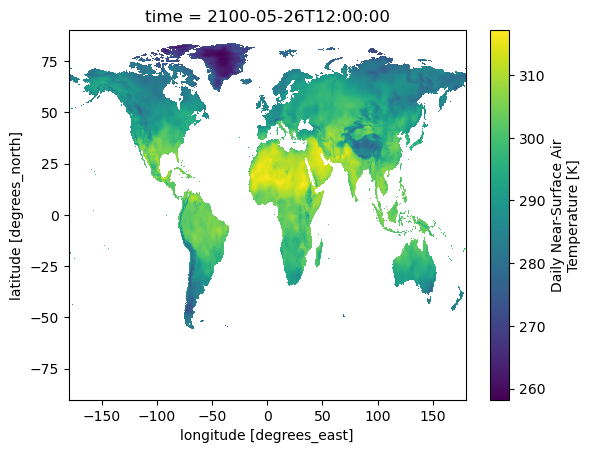

In [15]:
ds_model.tas.sel(time="2100-05-26").plot()